# A hawk kernel inside your jitted training step

Your training step is already `jax.jit(jax.value_and_grad(loss))`. Put a physics kernel inside the loss and keep
every line around it: `grad` reads the kernel's derivative from hawk, and the Param you fit is a plain float.

**Time:** ~5 min · **Runs on:** CPU, GPU if visible (picked up automatically) · **You need:** eagle, hawk and JAX

You will build: a drag coefficient fitted from noisy landing positions, with the gradient checked against finite
differences first.

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    from packaging.version import Version

    try:
        old = Version(importlib.metadata.version("jax")) < Version("0.11.2")
    except importlib.metadata.PackageNotFoundError:
        old = True
    if old:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", f"jax{extra}>=0.11.2"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "eagle"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/eagle/{ref}/{rel}", root / rel)
    (root / "docs/content/userguide/tutorials").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/userguide/tutorials")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent.parent / "_shared"))
from nb_helpers import plot_style
plot_style()

## The kernel, as a JAX function

One time step of a ball under gravity and quadratic drag. `cd` is a `Param`: one number for the whole batch, and
the thing we want to learn. `wrt` names what JAX may differentiate.

In [3]:
import os

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")  # leave GPU memory for your other libraries
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)  # the kernel runs in float64

import hawk
from hawk import Mutable, Param, Vector
from hawk.math import norm, vec

from eagle.frameworks import jax as eagle_jax


@hawk.kernel
def flight(r: Vector[3], v: Vector[3], cd: Param, dt: Param, g: Param,
           r_next: Mutable[Vector[3]], v_next: Mutable[Vector[3]]):
    a = vec(0.0, 0.0, -g) - cd * norm(v) * v
    v_new = v + dt * a
    v_next = v_new
    r_next = r + dt * v_new

step = eagle_jax.function(flight, wrt=("r", "v", "cd"))
step

KernelFunction('flight', inputs=['r', 'v', 'cd', 'dt', 'g'], outputs=['r_next', 'v_next'], wrt=['r', 'v', 'cd'])

## Fly 64 balls, observe where they land

`fly(cd)` unrolls 50 steps with `lax.scan`. The truth is `cd = 0.02`; the observations are the final positions
plus 5 cm of noise.

In [4]:
N, STEPS, DT, G, CD_TRUE = 64, 50, 0.02, 9.81, 0.02
k = jax.random.split(jax.random.key(1), 4)
speed = 10 + 10 * jax.random.uniform(k[0], (N,))
elevation = jnp.radians(30) + jnp.radians(40) * jax.random.uniform(k[1], (N,))
heading = jnp.pi * jax.random.uniform(k[2], (N,))
v0 = jnp.stack([speed * jnp.cos(elevation) * jnp.cos(heading),
                speed * jnp.cos(elevation) * jnp.sin(heading),
                speed * jnp.sin(elevation)])
r0 = jnp.zeros((3, N)).at[2].set(1.0)


def fly(cd):
    def body(state, _):
        r, v = step(*state, cd, DT, G)
        return (r, v), r
    (r, _), path = jax.lax.scan(body, (r0, v0), None, length=STEPS)
    return r, path


observed = fly(CD_TRUE)[0] + 0.05 * jax.random.normal(k[3], (3, N))
loss = lambda cd: ((fly(cd)[0] - observed) ** 2).mean()
print("loss at the truth:", round(float(loss(CD_TRUE)), 4), "| at cd = 0.1:", round(float(loss(0.1)), 2))

loss at the truth: 0.0025 | at cd = 0.1: 4.39


## Check the gradient first

`jax.test_util.check_grads` compares `grad` against finite differences, forward and reverse mode, to second order.
The derivative of the `Param` comes from the kernel hawk derives; you wrote no backward pass.

In [5]:
from jax.test_util import check_grads

check_grads(loss, (0.05,), order=2, modes=("fwd", "rev"), rtol=1e-4)
print("d loss / d cd at 0.05:", round(float(jax.grad(loss)(0.05)), 3), "(forward, reverse, first and second order all agree with finite differences)")

d loss / d cd at 0.05: 56.036 (forward, reverse, first and second order all agree with finite differences)


## Train

The usual jitted step: value and gradient, then a gradient-descent update. Start from a drag coefficient five times too big.

In [6]:
@jax.jit
def train_step(cd):
    value, grad = jax.value_and_grad(loss)(cd)
    return cd - 1e-4 * grad, value


cd, losses = 0.1, []
for _ in range(40):
    cd, value = train_step(cd)
    losses.append(float(value))
print(f"cd = {float(cd):.4f} (truth {CD_TRUE}); loss {losses[0]:.2f} -> {losses[-1]:.4f} (noise floor {0.05 ** 2:.4f})")

cd = 0.0200 (truth 0.02); loss 4.39 -> 0.0025 (noise floor 0.0025)


Left, six balls before and after the fit (dots are the observed landing points); right, the loss on the way down.


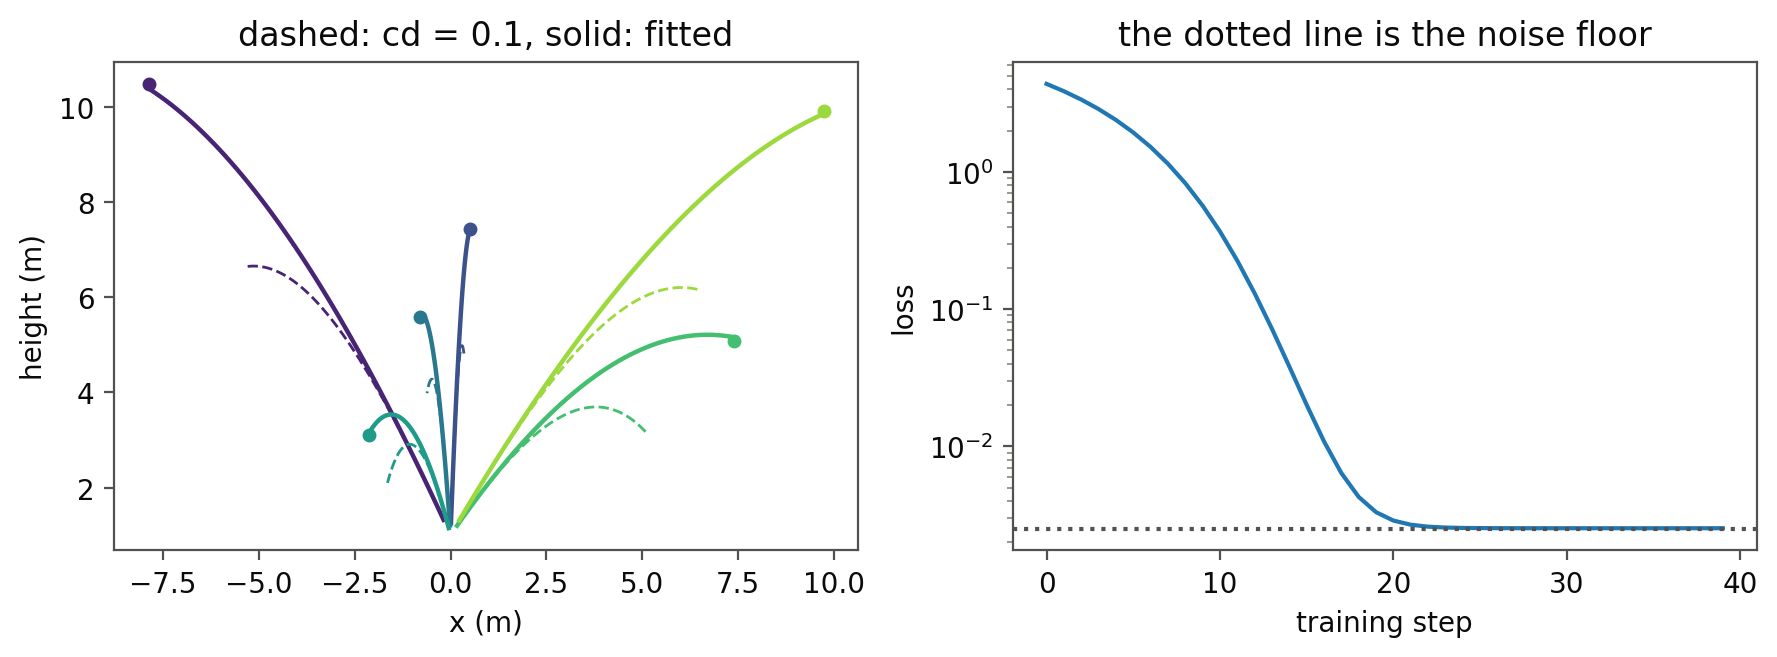
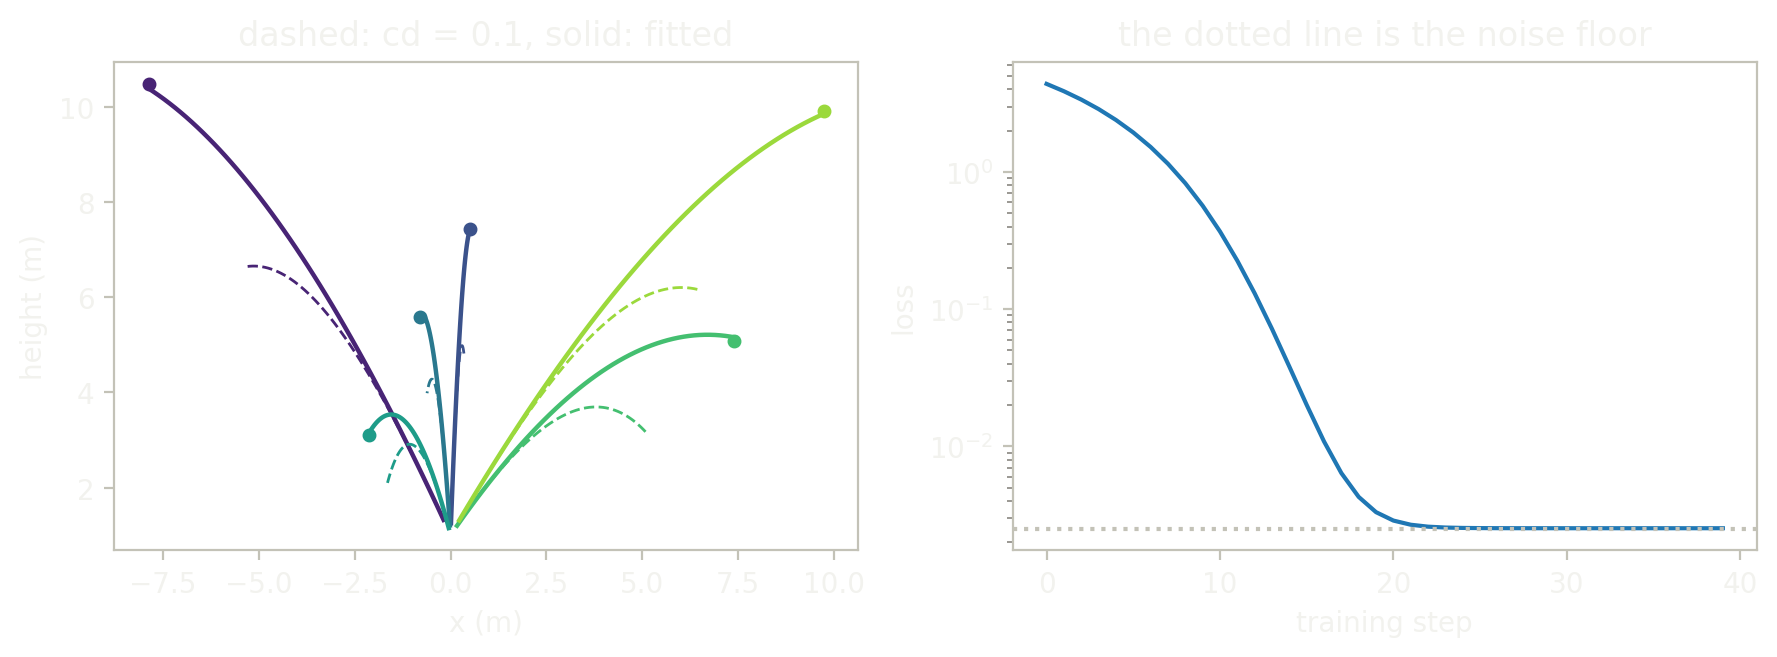

In [7]:
import matplotlib.pyplot as plt
from themed_figure import show

before, after = fly(0.1)[1], fly(float(cd))[1]
fig, (ax, bx) = plt.subplots(1, 2, figsize=(9, 3.4))
for i, colour in zip(range(6), plt.cm.viridis([0.1, 0.25, 0.4, 0.55, 0.7, 0.85])):
    ax.plot(before[:, 0, i], before[:, 2, i], "--", color=colour, lw=1)
    ax.plot(after[:, 0, i], after[:, 2, i], color=colour, lw=1.6)
    ax.plot(observed[0, i], observed[2, i], "o", color=colour, ms=4)
ax.set(xlabel="x (m)", ylabel="height (m)", title="dashed: cd = 0.1, solid: fitted")
bx.semilogy(losses)
bx.axhline(0.05 ** 2, color="#898781", ls=":")
bx.set(xlabel="training step", ylabel="loss", title="the dotted line is the noise floor")
plt.tight_layout()
show()

## What just happened

- `step` sat inside `lax.scan`, `jit` and `value_and_grad` like any other JAX function.
- The gradient of the `Param` `cd` came from a kernel hawk derived from `flight`.
- `check_grads` is the same test you would run on your own `jnp` step.

## Try this

Fit two things at once: add `g` to the parameters (`jax.grad(loss, argnums=(0, 1))` after giving `loss` a second
argument) and see which of the two the data pins down better.

## Next

- [Batches and Jacobians](jax_vmap_and_jacobians): `vmap` over trajectories and over Params, `jacfwd`, `hessian`.
- [A stepping loop in `lax.scan`](jax_simulation_loop): balls that land and stop.
- [eagle inside your JAX program](../../interop/use_eagle_with_jax): what crosses, what is refused, the limits.